# OU audit: noise is not slowing

## tl;dr
Finite-step, known-zero-mean Ornstein–Uhlenbeck episodes separate numerical bias from statistical identification. The stationary variance can increase identically under slower recovery and under larger noise. No tipping event is forecast here. The executed cells below provide the measured evidence and limitations.

## Context & Methods
Question: can variance identify slowing, and does Euler preserve the OU law?

### Key Assumptions
Scalar dX = −κX dt + σdW, κ>0, known mean zero, regular noiseless observation, stationary episodes with independent replicates within cells and paired mechanisms. φ=exp(−κΔt), q=σ²(1−exp(−2κΔt))/(2κ). Euler uses φ=1−κΔt, q=σ²Δt. Its stationary law requires 0<κΔt<2. Baselines and seeds were fixed in config.json. All references: referencias.bib.

### 1. Load configuration and saved audit

In [1]:
import csv, json
from pathlib import Path
import numpy as np
from IPython.display import display, Image
from src.ou import exact_transition, euler_transition, stationary_variance
config = json.loads(Path('config.json').read_text())
result = json.loads(Path('benchmarks/results.json').read_text())
print(json.dumps({'question': config['question'], 'checks': result['checks'], 'passed': result['passed']}, indent=2))
assert all(result['passed'].values())

{
  "question": "Can noise amplification mimic variance-based slowing, and can Euler discretization corrupt OU warning statistics?",
  "checks": {
    "max_transition_scaled_error": 1.4210854715202004e-14,
    "max_variance_match_error": 3.552713678800501e-15,
    "max_exact_mc_z": 2.473310511441326,
    "min_euler_relative_bias_at_dt1": 1.0,
    "min_ac1_population_separation_at_kappa01": 0.5369579768645172
  },
  "passed": {
    "max_transition_scaled_error": true,
    "max_variance_match_error": true,
    "max_exact_mc_z": true,
    "min_euler_relative_bias_at_dt1": true,
    "min_ac1_population_separation_at_kappa01": true
  }
}


## Data
84 simulations: seven step sizes × two sample counts × three seeds × two methods; 40 steps from X0=0 (horizon changes with Δt and is recorded). 3,200 stationary episode records: two mechanisms × four levels × two lengths × 200 replicates; standardized innovations are paired between mechanisms. No trajectories selected by realized collapse. Raw rows: benchmarks/*.csv. Representative paths: example_paths.npz; full draws regenerate from seeds.

### 2. Recompute the population counterexample

In [2]:
for level in config['identification']['kappa_levels']:
    slow = exact_transition(level, 1., 1.)
    noise = exact_transition(1., np.sqrt(1/level), 1.)
    assert np.isclose(stationary_variance(slow), stationary_variance(noise))
    print(f'level={level:.1f}: variance={stationary_variance(slow):.6f}; phi_slow={slow.phi:.6f}; phi_noise={noise.phi:.6f}')
print('Euler/exact stationary variance at kappa*dt=1:', stationary_variance(euler_transition(1.,1.,1.))/stationary_variance(exact_transition(1.,1.,1.)))

level=1.0: variance=0.500000; phi_slow=0.367879; phi_noise=0.367879
level=0.5: variance=1.000000; phi_slow=0.606531; phi_noise=0.367879
level=0.2: variance=2.500000; phi_slow=0.818731; phi_noise=0.367879
level=0.1: variance=5.000000; phi_slow=0.904837; phi_noise=0.367879
Euler/exact stationary variance at kappa*dt=1: 2.0


## Results
### 3. Review finite-sample dispersion
Known-mean second moment and conditional OLS coefficient are not sample-demeaned Pearson statistics. Undefined logarithmic rates are counted, not clipped or silently dropped.

In [3]:
with open('benchmarks/summary.csv') as f:
    summary = list(csv.DictReader(f))
for row in summary:
    if row['level']=='0.1':
        print({k:row[k] for k in ('family','length','variance_median','phi_median','kappa_median_valid_only','undefined_rate_count')})
print('Undefined rates across all episodes:', result['undefined_rates'])

{'family': 'slowing', 'length': '256', 'variance_median': '4.8708506385511505', 'phi_median': '0.9007123467525571', 'kappa_median_valid_only': '0.10456934279881604', 'undefined_rate_count': '0'}
{'family': 'slowing', 'length': '2048', 'variance_median': '4.881708221526327', 'phi_median': '0.9030539030118017', 'kappa_median_valid_only': '0.10197303878765758', 'undefined_rate_count': '0'}
{'family': 'noise_only', 'length': '256', 'variance_median': '4.97219079325256', 'phi_median': '0.3622424387146295', 'kappa_median_valid_only': '1.015441571689335', 'undefined_rate_count': '0'}
{'family': 'noise_only', 'length': '2048', 'variance_median': '5.00725606419428', 'phi_median': '0.3662842442088188', 'kappa_median_valid_only': '1.0043456668316513', 'undefined_rate_count': '0'}
Undefined rates across all episodes: 0


### 4. Inspect the numerical and statistical comparison
Left: exact finite-horizon second moments relative to the OU oracle, not Monte Carlo estimates. Middle: population variances coincide. Right: empirical 2.5–97.5% replicate quantiles at length 256, not confidence intervals for a population parameter.

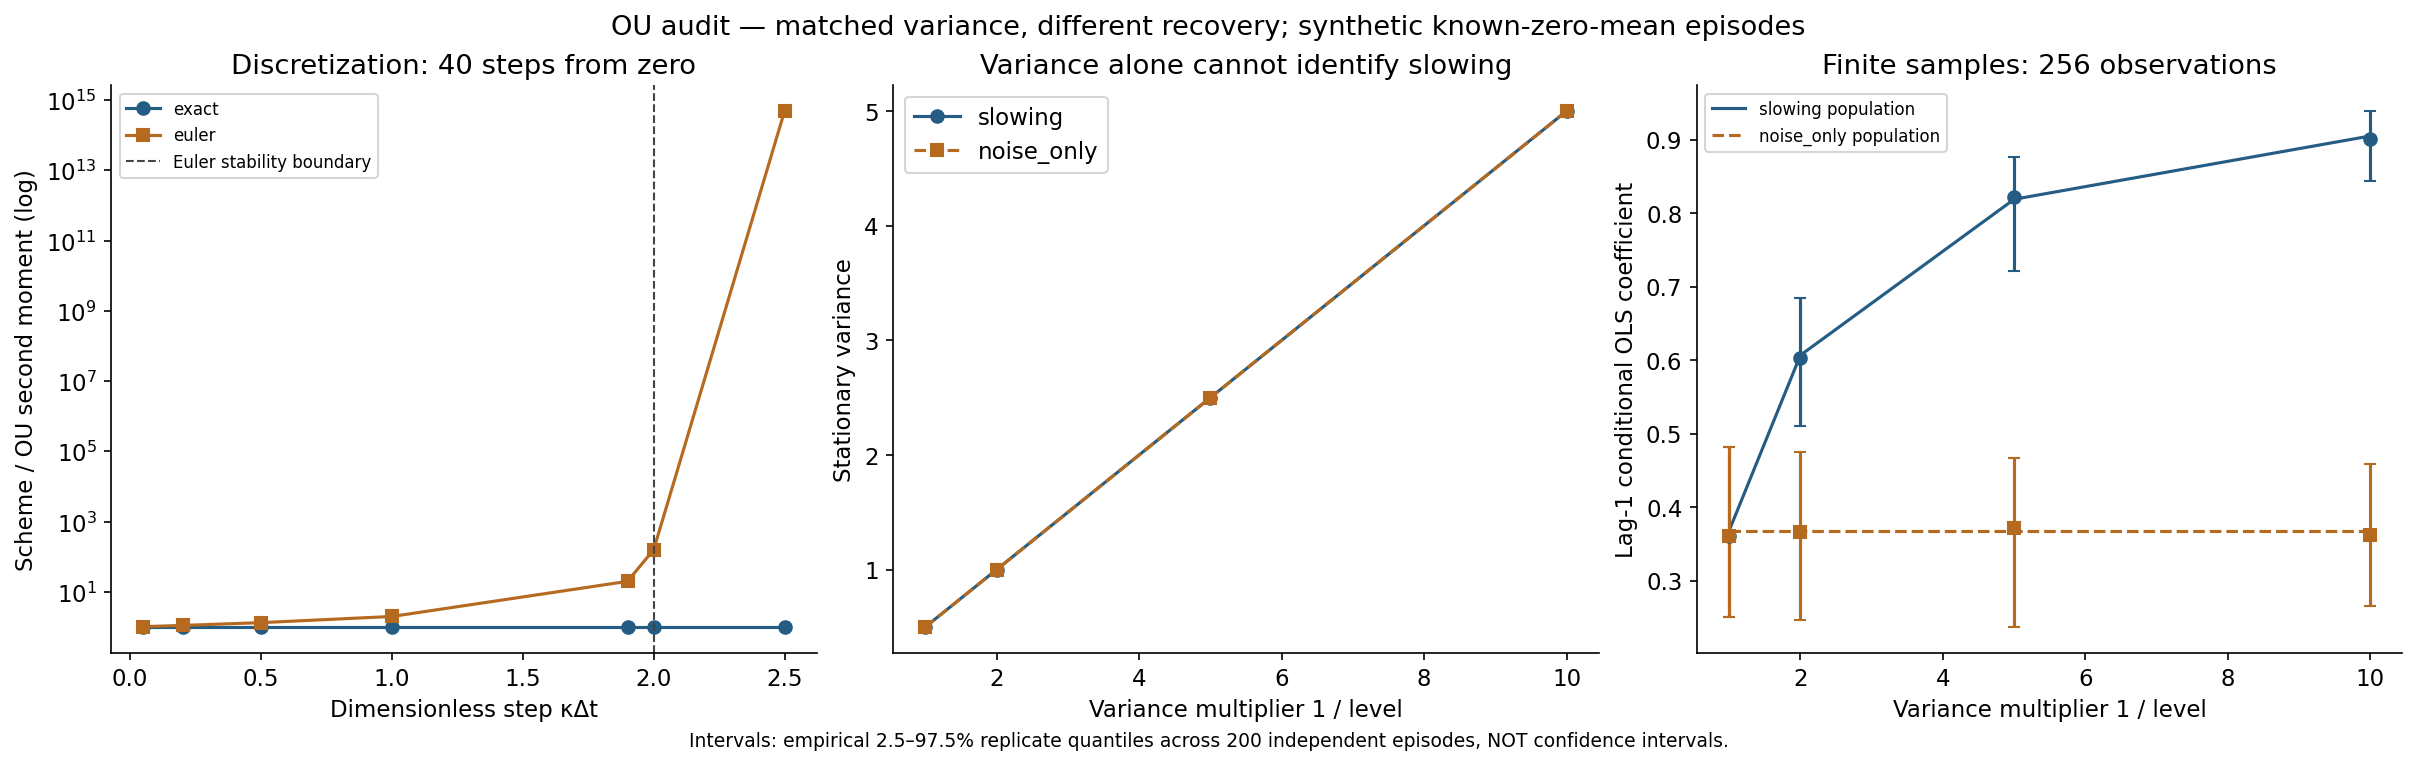

In [4]:
display(Image(filename='benchmarks/audit.png'))

## Takeaways
Variance alone does not identify recovery loss even at population level. Under these strong OU assumptions, lag-1 information can distinguish the two mechanisms. A coarse Euler step can double stationary variance, induce negative lag-1 correlation, or remove stationarity.

Limits: no nonlinear bifurcation, colored forcing, measurement noise, parameter drift, CUSUM comparison, prospective false-alarm calibration or financial validation. The population counterexample is algebraic; the simulation illustrates, not proves, its generalization to unknown processes. See informe.md for failures and resource caveats.

## Desarrollo experimental ampliado — 18 de octubre de 2026

Las siguientes celdas recalculan nuevos experimentos desde los modelos e inputs. Los resultados históricos anteriores se conservan como evidencia separada. Cada experimento declara su alcance; no eleva automáticamente la madurez del proyecto.

### 5. Identificación con error de medición
Si $Y_t=X_t+e_t$, con ruido blanco independiente de varianza $\tau^2$, entonces $\gamma_Y(0)=V+\tau^2$, $\gamma_Y(1)=V\phi$ y $\gamma_Y(2)=V\phi^2$, donde $V=\sigma^2/(2\kappa)$. El cociente de lag uno queda atenuado: $\gamma_Y(1)/\gamma_Y(0)=\phi V/(V+\tau^2)$. La recuperación aparente puede aumentar sin cambiar la dinámica latente.

En población, $\gamma_Y(2)/\gamma_Y(1)=\phi$ elimina ese ruido. En muestra, dividir por una autocovarianza pequeña puede amplificar la dispersión. Compararemos ambos estimadores sin recortar resultados fuera de $(0,1)$.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
from src.ou import simulate, diagnostics
rng = np.random.default_rng(20261018)
true_kappa, dt, observations, replicates = .3, 1., 512, 300
transition = exact_transition(true_kappa, 1., dt)
latent = simulate(transition, rng.normal(size=(replicates, observations)), stationary=True)
noise_draws = rng.normal(size=latent.shape)
V = stationary_variance(transition)
noise_rows = []
for ratio in [0., .25, 1., 4.]:
    observed = latent + np.sqrt(ratio*V)*noise_draws
    g0 = np.mean(observed**2, axis=1)
    g1 = np.mean(observed[:, 1:]*observed[:, :-1], axis=1)
    g2 = np.mean(observed[:, 2:]*observed[:, :-2], axis=1)
    for name, estimates, oracle in [('lag1',g1/g0,transition.phi/(1+ratio)),
                                    ('lag2/lag1',g2/g1,transition.phi)]:
        valid = (estimates>0)&(estimates<1)
        noise_rows.append(dict(noise_to_signal=ratio, estimator=name,
            population_phi=oracle, median_phi=np.median(estimates),
            q025=np.quantile(estimates,.025),q975=np.quantile(estimates,.975),
            undefined_rate=int((~valid).sum()),
            median_kappa_valid_only=np.median(-np.log(estimates[valid])/dt)))
noise_table=pd.DataFrame(noise_rows)
display(noise_table.round(4))
assert np.allclose(noise_table.query("estimator == 'lag2/lag1'").population_phi,transition.phi)


,noise_to_signal,estimator,population_phi,median_phi,q025,q975,undefined_rate,median_kappa_valid_only
0,0.00,lag1,0.7408,0.7359,0.6737,0.7821,0,0.3067
1,0.00,lag2/lag1,0.7408,0.7329,0.6532,0.7966,0,0.3108
2,0.25,lag1,0.5927,0.5890,0.5068,0.6628,0,0.5293
3,0.25,lag2/lag1,0.7408,0.7350,0.6189,0.8268,0,0.3079
4,1.00,lag1,0.3704,0.3654,0.2816,0.4612,0,1.0067
5,1.00,lag2/lag1,0.7408,0.7345,0.5189,0.9204,1,0.3093
6,4.00,lag1,0.1482,0.1454,0.0667,0.2456,1,1.9278
7,4.00,lag2/lag1,0.7408,0.7071,0.1512,1.6587,66,0.4119


### 6. Sesgo y dispersión son problemas diferentes
Los intervalos siguientes son cuantiles entre 300 réplicas independientes; no son intervalos de confianza construidos para una trayectoria. Se usan las mismas innovaciones y ruido estandarizado entre niveles para facilitar la comparación.

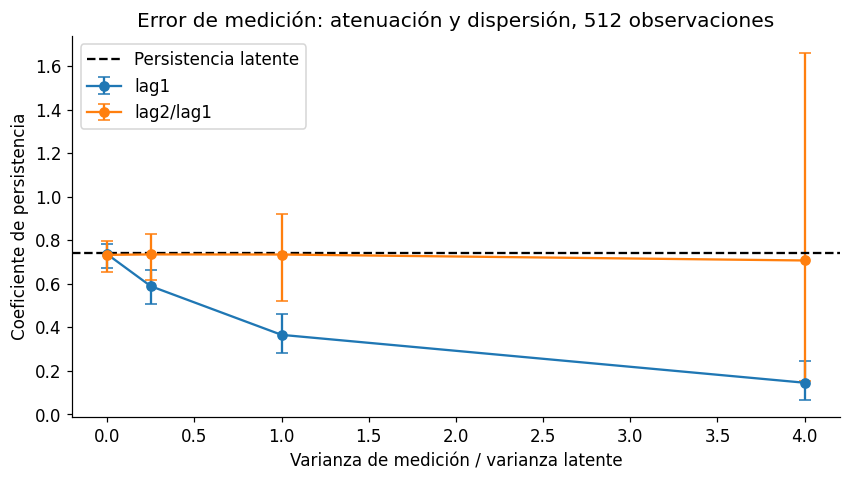

Casos con tasa logarítmica indefinida: 68


In [6]:
fig, ax=plt.subplots()
for name, group in noise_table.groupby('estimator',sort=False):
    ax.errorbar(group.noise_to_signal,group.median_phi,
        yerr=[group.median_phi-group.q025,group.q975-group.median_phi],fmt='o-',capsize=4,label=name)
ax.axhline(transition.phi,color='black',linestyle='--',label='Persistencia latente')
ax.set(xlabel='Varianza de medición / varianza latente',ylabel='Coeficiente de persistencia',title='Error de medición: atenuación y dispersión, 512 observaciones')
ax.legend(); plt.show()
print('Casos con tasa logarítmica indefinida:',int(noise_table.undefined_rate.sum()))

### 7. Frecuencia frente a horizonte: experimento controlado
Fijar el número de pasos al cambiar $\Delta t$ cambia también el horizonte. Ahora fijamos $T=64$ y variamos solamente la frecuencia. Más observaciones no equivalen a más tiempo de recuperación observado. El error se mide contra $\kappa=0.3$ con 300 réplicas; los ruidos entre frecuencias son independientes.

In [7]:
frequency_rows=[]
for step in [.125,.25,.5,1.,2.]:
    paths=simulate(exact_transition(true_kappa,1.,step),rng.normal(size=(300,int(64/step)+1)),stationary=True)
    _,_,rates=diagnostics(paths,step)
    valid=np.isfinite(rates)
    frequency_rows.append(dict(dt=step,horizon=64,observations=paths.shape[1],
        invalid=int((~valid).sum()),bias_valid=float(np.mean(rates[valid]-true_kappa)),
        rmse_valid=float(np.sqrt(np.mean((rates[valid]-true_kappa)**2)))))
display(pd.DataFrame(frequency_rows).round(5))
assert all(row['horizon']==64 for row in frequency_rows)
assert np.allclose(stationary_variance(transition),1/(2*true_kappa))

,dt,horizon,observations,invalid,bias_valid,rmse_valid
0,0.125,64,513,0,0.03564,0.12218
1,0.250,64,257,0,0.02749,0.10497
2,0.500,64,129,0,0.03302,0.11525
3,1.000,64,65,0,0.04853,0.14879
4,2.000,64,33,0,0.04697,0.16311


### Interpretación y límites adicionales
La corrección lag2/lag1 exige error de medición blanco e independiente; con error serialmente correlacionado deja de identificar la persistencia latente. Las tasas se resumen condicionadas a estar definidas y se informa cuántas fallan. No se estima una alerta de crisis ni se calibra una prueba de raíz unitaria. La tabla de frecuencia separa el horizonte del tamaño muestral, pero no es una comparación de trayectorias acopladas.

### Lectura de los resultados ejecutados

En esta ejecución, los ocho grupos de estimadores acumulan **68 tasas logarítmicas indefinidas** (conteo de resultados de estimador, no de trayectorias únicas). La figura muestra que el cociente lag2/lag1 conserva mejor el centro poblacional, pero amplía mucho la dispersión con ruido alto. Corregir el sesgo no garantiza precisión; reportar sólo tasas válidas ocultaría una parte del riesgo de estimación.